<a href="https://colab.research.google.com/github/eaedk/Machine-Learning-Tutorials-Updated/blob/main/00_start_here/02_competition_playbook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🏆 The Competition Playbook: how not to fall off the leaderboard

Every competition veteran has a story: *"I was 3rd on the public leaderboard… and finished 212th."*
This notebook is a laboratory. With small simulations, you will **see with your own eyes** the four ideas that
separate good competitors from lucky ones:

1. 🎲 **The shake-up**: why the public leaderboard lies, and why your local validation is your real compass.
2. 🧩 **Choosing the right split**: when random K-fold gives you a fake score.
3. 🕳️ **Leakage**: how to get 90% accuracy on pure noise (and how to avoid it).
4. 🕵️ **Adversarial validation**: are train and test really alike?
5. 🤝 **Ensembling**: why a team of average models beats a single star.

Everything runs in a few seconds on synthetic data, so you can change the parameters and replay.

In [1]:
# ⚙️ Setup: run me first! Finds the course toolkit `mlquest` (Windows, macOS, Linux and Colab).
import os, sys, subprocess, pathlib
if "google.colab" in sys.modules:  # on Colab: grab the repo (once) and the few missing packages
    if not pathlib.Path("/content/Machine-Learning-Tutorials-Updated").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/eaedk/Machine-Learning-Tutorials-Updated", "/content/Machine-Learning-Tutorials-Updated"], check=True)
    os.chdir("/content/Machine-Learning-Tutorials-Updated")
ROOT = pathlib.Path.cwd()
while not (ROOT / "mlquest").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from mlquest import *  # paths, seed_everything, get_device, quest/checkpoint, Leaderboard...
set_style()
SEED = seed_everything(42)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, cross_val_score, KFold, GroupKFold, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, roc_auc_score

quest("The Competition Playbook", chapter="Chapter 0 · Start here", xp=150)

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
🗺️  QUEST · The Competition Playbook
   Chapter 0 · Start here
   Reward: up to 150 XP
   You are: 🥚 Curious Rookie   ░░░░░░░░░░░░░░░░░░░░░░░░ 0/100 XP
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


## 1. 🎲 The shake-up, simulated

**Setting.** A competition with 600 training rows and a test set of 2 000 rows. The platform shows a *public* score
computed on 20% of the test set; the final ranking uses the hidden 80% (*private*).

**Experiment.** A competitor makes **150 submissions**: random models with random hyperparameters. For each one we
record its **public** score, its **private** score, and its **5-fold cross-validation** score on the training data.

Which submission would you pick at the end? The one with the best *public* score, or the best *CV* score?

In [3]:
X, y = make_classification(n_samples=2600, n_features=30, n_informative=6, flip_y=0.15, class_sep=0.8, random_state=SEED)
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=600, random_state=SEED, stratify=y)
rng = np.random.default_rng(SEED)
public = rng.random(len(y_test)) < 0.20          # 20% of the test rows are "public"

rows = []
for i in range(150):
    kind = rng.choice(["logreg", "rf", "knn"])
    if kind == "logreg":
        model = LogisticRegression(C=10 ** rng.uniform(-3, 2), max_iter=2000)
    elif kind == "rf":
        model = RandomForestClassifier(n_estimators=60, max_depth=int(rng.integers(2, 20)),
                                       max_features=float(rng.uniform(0.1, 1)), random_state=i, n_jobs=-1)
    else:
        model = KNeighborsClassifier(n_neighbors=int(rng.integers(1, 60)))
    cv = cross_val_score(model, X_train, y_train, cv=5).mean()
    pred = model.fit(X_train, y_train).predict(X_test)
    rows.append({"model": kind, "cv": cv,
                 "public": accuracy_score(y_test[public], pred[public]),
                 "private": accuracy_score(y_test[~public], pred[~public])})
subs = pd.DataFrame(rows)
subs["private_rank"] = subs["private"].rank(ascending=False).astype(int)
subs.sort_values("public", ascending=False).head()

,model,cv,public,private,private_rank
60,rf,0.823333,0.791667,0.773869,25
10,rf,0.805000,0.789216,0.769472,46
113,rf,0.805000,0.786765,0.763819,75
59,rf,0.813333,0.781863,0.772613,30
84,rf,0.815000,0.781863,0.771985,34


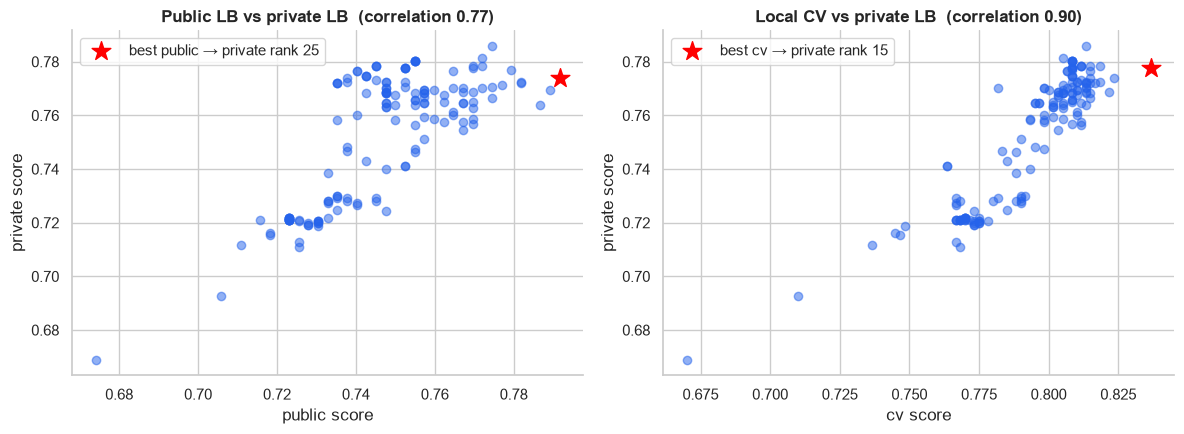

Picked by public LB → private rank 25 / 150
Picked by local CV  → private rank 15 / 150


In [4]:
best_public = subs.loc[subs["public"].idxmax()]
best_cv = subs.loc[subs["cv"].idxmax()]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col, best, title in [(axes[0], "public", best_public, "Public LB vs private LB"),
                             (axes[1], "cv", best_cv, "Local CV vs private LB")]:
    ax.scatter(subs[col], subs["private"], alpha=0.5)
    ax.scatter(best[col], best["private"], s=200, c="red", marker="*", label=f"best {col} → private rank {best['private_rank']}")
    r = np.corrcoef(subs[col], subs["private"])[0, 1]
    ax.set(xlabel=f"{col} score", ylabel="private score", title=f"{title}  (correlation {r:.2f})")
    ax.legend()
plt.tight_layout(); plt.show()
print(f"Picked by public LB → private rank {best_public['private_rank']} / 150")
print(f"Picked by local CV  → private rank {best_cv['private_rank']} / 150")

**What you should see:** the public score is computed on only ~400 rows, so it is *noisy*: the best public
submission is often just a lucky one. The 5-fold CV uses all 600 training rows several times and correlates better
with the private leaderboard.

> 🧠 **Rule #1: trust your CV.** Use the public leaderboard as one more validation fold, never as your only guide.
> At the end, most platforms let you **select 2 final submissions**: pick your best CV model and a robust ensemble.

🔁 *Replay:* change `0.20` (size of the public part) or `flip_y` (label noise). When is the shake-up worst?

In [5]:
checkpoint("playbook/shakeup", xp=30)

✅ Checkpoint · playbook/shakeup (+30 XP)
   ███████░░░░░░░░░░░░░░░░░ 30/100 XP


## 2. 🧩 Choosing the right split: the hidden group trap

Imagine a medical challenge: **100 patients**, 10 measurements each. The test set contains **new patients**.
Each patient has their own "signature" (age, physiology…); sickness depends only a little on it.

If you use a plain `KFold`, rows of the *same patient* land both in training and validation folds. The model
recognises the patient instead of learning the disease. Let's measure the damage.

In [6]:
n_patients, per_patient = 100, 10

def make_patients(n, rng):
    """Each patient = a unique profile (5 numbers). Sickness depends a bit on profile[0] and a lot on luck."""
    signature = rng.normal(size=(n, 5))
    sick = (signature[:, 0] + rng.normal(scale=1.0, size=n)) > 0
    g = np.repeat(np.arange(n), per_patient)
    X = np.hstack([signature[g] + rng.normal(scale=0.2, size=(len(g), 5)),   # measurements ≈ the profile
                   rng.normal(size=(len(g), 5))])                             # + useless noise columns
    return X, sick[g].astype(int), g

Xg, yg, groups = make_patients(n_patients, rng)
X_new, y_new, _ = make_patients(40, rng)                       # 40 brand-new patients = the "test set"

model = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
kfold = cross_val_score(model, Xg, yg, cv=KFold(5, shuffle=True, random_state=SEED)).mean()
group = cross_val_score(model, Xg, yg, cv=GroupKFold(5), groups=groups).mean()
truth = accuracy_score(y_new, model.fit(Xg, yg).predict(X_new))

pd.DataFrame({"validation": ["KFold (random rows)", "GroupKFold (by patient)", "Reality: new patients"],
              "accuracy": [kfold, group, truth]}).round(3)

,validation,accuracy
0,KFold (random rows),0.895
1,GroupKFold (by patient),0.768
2,Reality: new patients,0.638


`KFold` promises a near-perfect model, because it recognises patients it has already seen. On new patients the
score collapses, and `GroupKFold` predicted it.

> 🧠 **Rule #2: your validation must mimic the test.** New customers → group by customer. Future dates → split by
> time (`TimeSeriesSplit`, see the time-series track). Imbalanced classes → `StratifiedKFold`.

In [7]:
checkpoint("playbook/groups", xp=30)

✅ Checkpoint · playbook/groups (+30 XP)
   ██████████████░░░░░░░░░░ 60/100 XP


## 3. 🕳️ Leakage: 90% accuracy on pure noise

A famous trap (described in *The Elements of Statistical Learning*). We create **random labels** and **5 000 random
features**: there is *nothing* to learn. Then we:

1. select the 20 features most correlated with the target **using all the data**,
2. *then* cross-validate a model on those features.

In [8]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import make_pipeline

X_noise = rng.normal(size=(100, 5000))
y_noise = rng.integers(0, 2, size=100)

# ❌ Wrong: feature selection sees the whole dataset (including future validation rows)
X_selected = SelectKBest(f_classif, k=20).fit_transform(X_noise, y_noise)
wrong = cross_val_score(LogisticRegression(max_iter=1000), X_selected, y_noise, cv=5).mean()

# ✅ Right: selection is a step of the pipeline, re-fitted inside each training fold
pipe = make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression(max_iter=1000))
right = cross_val_score(pipe, X_noise, y_noise, cv=5).mean()

print(f"❌ Selection before CV : {wrong:.0%} accuracy on random labels (!!)")
print(f"✅ Selection inside CV : {right:.0%} accuracy (≈ coin flip, the truth)")

❌ Selection before CV : 86% accuracy on random labels (!!)
✅ Selection inside CV : 42% accuracy (≈ coin flip, the truth)


> 🧠 **Rule #3: every step that *learns* from data (scaling, imputation, encoding, feature selection, resampling,
> target encoding) must be fitted on training folds only.** The easy way: put it in a scikit-learn `Pipeline`.

Other classic leaks to watch for in competitions: a column filled *after* the event you predict (e.g. "claim_paid"
to predict a claim), ids that encode time, duplicated rows across train and test, and features built with the target.

In [9]:
checkpoint("playbook/leakage", xp=30)

✅ Checkpoint · playbook/leakage (+30 XP)
   █████████████████████░░░ 90/100 XP


## 4. 🕵️ Adversarial validation: do train and test look alike?

A clever trick from Kaggle: label train rows `0` and test rows `1`, then train a classifier to tell them apart.
- **AUC ≈ 0.5** → indistinguishable: a random K-fold will be reliable. 😌
- **AUC ≫ 0.5** → the test set is different (other period, other region…). Find *which* features betray the
  difference (feature importance) and build a validation set that looks like the test. 😬

In [10]:
def adversarial_auc(train_X, test_X):
    Xa = np.vstack([train_X, test_X])
    ya = np.r_[np.zeros(len(train_X)), np.ones(len(test_X))]
    clf = HistGradientBoostingClassifier(max_iter=100)
    return cross_val_score(clf, Xa, ya, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="roc_auc").mean()

same = adversarial_auc(X_train, X_test)
X_shifted = X_test.copy(); X_shifted[:, 3] += 1.0            # e.g. prices measured one year later
shifted = adversarial_auc(X_train, X_shifted)
print(f"Same distribution : AUC = {same:.2f}")
print(f"Feature 3 shifted : AUC = {shifted:.2f}  → investigate feature 3!")

Same distribution : AUC = 0.53
Feature 3 shifted : AUC = 0.74  → investigate feature 3!


In [11]:
checkpoint("playbook/adversarial", xp=30)

✅ Checkpoint · playbook/adversarial (+30 XP)
🎉 LEVEL UP! You are now 🐣 Data Explorer
   ██░░░░░░░░░░░░░░░░░░░░░░ 120/300 XP


## 5. 🤝 Ensembling: the wisdom of crowds

The Netflix Prize was won by blending hundreds of models. Why does it work? Different models make **different
mistakes**; averaging their probabilities cancels part of the errors.

In [12]:
models = {
    "LogReg": make_pipeline(LogisticRegression(max_iter=2000)),
    "RandomForest": RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    "GradientBoosting": HistGradientBoostingClassifier(random_state=SEED),
    "KNN": KNeighborsClassifier(n_neighbors=25),
}
lb = Leaderboard("playbook_ensemble", metric="AUC")
probas = {}
for name, m in models.items():
    probas[name] = m.fit(X_train, y_train).predict_proba(X_test)[:, 1]
    lb.add(name, roc_auc_score(y_test, probas[name]))
lb.add("Average of the 4 🤝", roc_auc_score(y_test, np.mean(list(probas.values()), axis=0)))
lb.show()

📋 LogReg: AUC = 0.75910


📋 RandomForest: AUC = 0.84057  👑 new best!


📋 GradientBoosting: AUC = 0.83414
📋 KNN: AUC = 0.84029
📋 Average of the 4 🤝: AUC = 0.84083  👑 new best!


,,model,AUC
rank,,,
1,🥇,Average of the 4 🤝,0.84083
2,🥈,RandomForest,0.84057
3,🥉,KNN,0.84029
4,,GradientBoosting,0.83414
5,,LogReg,0.75910


In [13]:
pd.DataFrame(probas).corr().round(2).style.background_gradient(cmap="Blues").format("{:.2f}")

,LogReg,RandomForest,GradientBoosting,KNN
LogReg,1.00,0.82,0.80,0.74
RandomForest,0.82,1.00,0.90,0.88
GradientBoosting,0.80,0.90,1.00,0.82
KNN,0.74,0.88,0.82,1.00


The less correlated the models (see the matrix above), the more the average helps. In practice: blend a gradient
boosting model with a neural network or a linear model rather than three gradient boosting models with similar
settings.

## 6. 📋 The competitor's checklist

Before the competition
- [ ] Read the rules, the **metric**, the data description and the forum (discussions often reveal traps).
- [ ] Look at `SampleSubmission.csv` first.

During
- [ ] Build a **dumb baseline** and submit it on day 1 (it validates your whole pipeline end to end).
- [ ] Set up a **CV that correlates with the leaderboard**, then iterate on CV.
- [ ] Log every experiment (the `Leaderboard` helper, a spreadsheet, or MLflow/W&B).
- [ ] Fix your seeds, keep your code in git.
- [ ] Teaming up is allowed in most competitions: diverse teammates make diverse models (see §5).

At the end
- [ ] Select **two** final submissions: best CV + most robust ensemble.
- [ ] Write a short solution summary. Read the winners' solutions: it is the fastest way to learn.

In [14]:
badge("Playbook Strategist", "♟️", "You know the traps. Time to play: open 01_tabular/01_classification_quest_titanic.ipynb")
progress()

╔═════════════════════════════════════════╗
║ ♟️  BADGE UNLOCKED: Playbook Strategist ║
╚═════════════════════════════════════════╝
You know the traps. Time to play: open 01_tabular/01_classification_quest_titanic.ipynb
🐣 Data Explorer
██░░░░░░░░░░░░░░░░░░░░░░ 120/300 XP
Checkpoints unlocked: 4
Badges: ♟️ Playbook Strategist
